# Customer Churn Prediction

## Week 10: Data Preprocessing & Feature Engineering

**Objective:** To clean, transform, and prepare customer data for machine learning by applying encoding, feature scaling, outlier detection, feature engineering, and feature selection techniques. Finally, build and evaluate a Random Forest classification pipeline to predict customer churn.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("customer_churn.csv")

df.head()

,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [3]:
df.shape

(500, 9)

In [4]:
df.columns

Index(['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract',
       'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        500 non-null    object
 1   Tenure            500 non-null    int64 
 2   MonthlyCharges    500 non-null    int64 
 3   TotalCharges      500 non-null    int64 
 4   Contract          500 non-null    object
 5   PaymentMethod     500 non-null    object
 6   PaperlessBilling  500 non-null    object
 7   SeniorCitizen     500 non-null    int64 
 8   Churn             500 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 35.3+ KB


In [6]:
df.isnull().sum()

CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64

In [7]:
df["Churn"].value_counts()

Churn
0    447
1     53
Name: count, dtype: int64

In [8]:
df["Churn"].value_counts(normalize=True) * 100

Churn
0    89.4
1    10.6
Name: proportion, dtype: float64

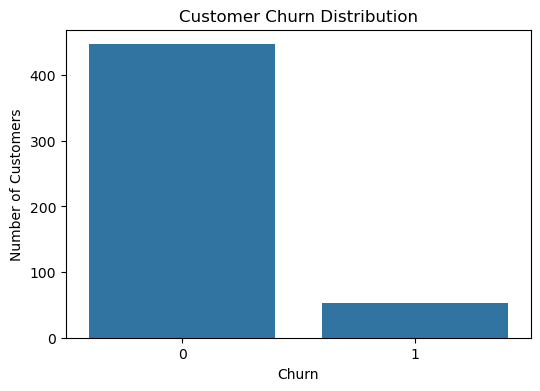

In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [10]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df["PaperlessBilling_Encoded"] = le.fit_transform(df["PaperlessBilling"])
df[["PaperlessBilling", "PaperlessBilling_Encoded"]].head(10)

,PaperlessBilling,PaperlessBilling_Encoded
0,No,0
1,Yes,1
2,No,0
3,No,0
4,No,0
5,No,0
6,No,0
7,No,0
8,No,0
9,Yes,1


In [11]:
df["Contract"].unique()

array(['One year', 'Month-to-month', 'Two year'], dtype=object)

In [12]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
contract_encoded = encoder.fit_transform(df[["Contract"]])

In [13]:
encoder.get_feature_names_out(["Contract"])

array(['Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year'], dtype=object)

In [14]:
contract_encoded[:5]

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.]])

In [15]:
contract_df = pd.DataFrame(
    contract_encoded,
    columns=encoder.get_feature_names_out(["Contract"])
)

contract_df.head()

,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0.0,1.0,0.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,1.0,0.0


In [16]:
from sklearn.preprocessing import OrdinalEncoder
education = pd.DataFrame({
    "Education": [
        "School",
        "Graduate",
        "Postgraduate",
        "Graduate",
        "School"
    ]
})
ordinal_encoder = OrdinalEncoder(
    categories=[["School", "Graduate", "Postgraduate"]]
)

education["Education_Encoded"] = ordinal_encoder.fit_transform(
    education[["Education"]]
)

education

,Education,Education_Encoded
0,School,0.0
1,Graduate,1.0
2,Postgraduate,2.0
3,Graduate,1.0
4,School,0.0


In [17]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scale_data = df[["Tenure", "MonthlyCharges"]]

scale_data.head()
minmax_scaler = MinMaxScaler()

minmax_scaled = minmax_scaler.fit_transform(scale_data)

minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=["Tenure_MinMax", "MonthlyCharges_MinMax"]
)

minmax_df.head()
standard_scaler = StandardScaler()

standard_scaled = standard_scaler.fit_transform(scale_data)

standard_df = pd.DataFrame(
    standard_scaled,
    columns=["Tenure_Standard", "MonthlyCharges_Standard"]
)

standard_df.head()

,Tenure_Standard,MonthlyCharges_Standard
0,-1.478807,-0.959185
1,-0.752287,-0.012290
2,-0.461679,-1.596890
3,0.797622,-1.635539
4,-0.994460,1.379066


In [18]:
comparison_df = pd.concat(
    [
        scale_data.head().reset_index(drop=True),
        minmax_df.head().reset_index(drop=True),
        standard_df.head().reset_index(drop=True)
    ],
    axis=1
)

comparison_df

,Tenure,MonthlyCharges,Tenure_MinMax,MonthlyCharges_MinMax,Tenure_Standard,MonthlyCharges_Standard
0,6,64,0.071429,0.245810,-1.478807,-0.959185
1,21,113,0.285714,0.519553,-0.752287,-0.012290
2,27,31,0.371429,0.061453,-0.461679,-1.596890
3,53,29,0.742857,0.050279,0.797622,-1.635539
4,16,185,0.214286,0.921788,-0.994460,1.379066


In [19]:
Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
outliers_iqr = df[
    (df["MonthlyCharges"] < lower_limit) |
    (df["MonthlyCharges"] > upper_limit)
]

print("Number of outliers:", len(outliers_iqr))
outliers_iqr[["MonthlyCharges"]].head()

Q1: 67.0
Q3: 158.0
IQR: 91.0
Lower Limit: -69.5
Upper Limit: 294.5
Number of outliers: 0


,MonthlyCharges


In [20]:
from scipy.stats import zscore

df["MonthlyCharges_Zscore"] = zscore(df["MonthlyCharges"])

outliers_zscore = df[
    df["MonthlyCharges_Zscore"].abs() > 3
]

print("Number of Z-score outliers:", len(outliers_zscore))

outliers_zscore[
    ["MonthlyCharges", "MonthlyCharges_Zscore"]
].head()

Number of Z-score outliers: 0


,MonthlyCharges,MonthlyCharges_Zscore


In [21]:
# 1. Average monthly spending based on total charges
df["AvgMonthlySpending"] = (
    df["TotalCharges"] / df["Tenure"].replace(0, np.nan)
)

# 2. Estimated yearly charges
df["YearlyCharges"] = df["MonthlyCharges"] * 12

# 3. Customer tenure in years
df["TenureYears"] = df["Tenure"] / 12

# 4. High monthly charges indicator
df["HighMonthlyCharges"] = (
    df["MonthlyCharges"] > df["MonthlyCharges"].median()
).astype(int)

# 5. Long-term customer indicator
df["LongTermCustomer"] = (
    df["Tenure"] >= 24
).astype(int)

df[
    [
        "Tenure",
        "MonthlyCharges",
        "TotalCharges",
        "AvgMonthlySpending",
        "YearlyCharges",
        "TenureYears",
        "HighMonthlyCharges",
        "LongTermCustomer"
    ]
].head()

,Tenure,MonthlyCharges,TotalCharges,AvgMonthlySpending,YearlyCharges,TenureYears,HighMonthlyCharges,LongTermCustomer
0,6,64,1540,256.666667,768,0.500000,0,0
1,21,113,1753,83.476190,1356,1.750000,0,0
2,27,31,1455,53.888889,372,2.250000,0,1
3,53,29,7150,134.905660,348,4.416667,0,1
4,16,185,1023,63.937500,2220,1.333333,1,0


In [22]:
df[
    [
        "Tenure",
        "MonthlyCharges",
        "TotalCharges",
        "AvgMonthlySpending",
        "YearlyCharges",
        "TenureYears",
        "HighMonthlyCharges",
        "LongTermCustomer"
    ]
].head(5).to_string(index=False)

' Tenure  MonthlyCharges  TotalCharges  AvgMonthlySpending  YearlyCharges  TenureYears  HighMonthlyCharges  LongTermCustomer\n      6              64          1540          256.666667            768     0.500000                   0                 0\n     21             113          1753           83.476190           1356     1.750000                   0                 0\n     27              31          1455           53.888889            372     2.250000                   0                 1\n     53              29          7150          134.905660            348     4.416667                   0                 1\n     16             185          1023           63.937500           2220     1.333333                   1                 0'

In [23]:
print("Zero-tenure customers:", (df["Tenure"] == 0).sum())
print("Missing AvgMonthlySpending:", df["AvgMonthlySpending"].isna().sum())

Zero-tenure customers: 0
Missing AvgMonthlySpending: 0


In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["CustomerID", "Churn", "MonthlyCharges_Zscore"])
y = df["Churn"]

X = pd.get_dummies(
    X,
    columns=["Contract", "PaymentMethod", "PaperlessBilling"],
    drop_first=True,
    dtype=int
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 15)
Target shape: (500,)


LongTermCustomer                 -0.516133
TenureYears                      -0.509208
Tenure                           -0.509208
AvgMonthlySpending                0.404714
Contract_One year                -0.157484
MonthlyCharges                    0.107381
YearlyCharges                     0.107381
HighMonthlyCharges                0.087218
Contract_Two year                -0.075525
PaymentMethod_Credit Card         0.069635
SeniorCitizen                    -0.018114
PaperlessBilling_Yes              0.016145
PaperlessBilling_Encoded          0.016145
PaymentMethod_Electronic Check    0.010007
TotalCharges                      0.004250
Name: Churn, dtype: float64


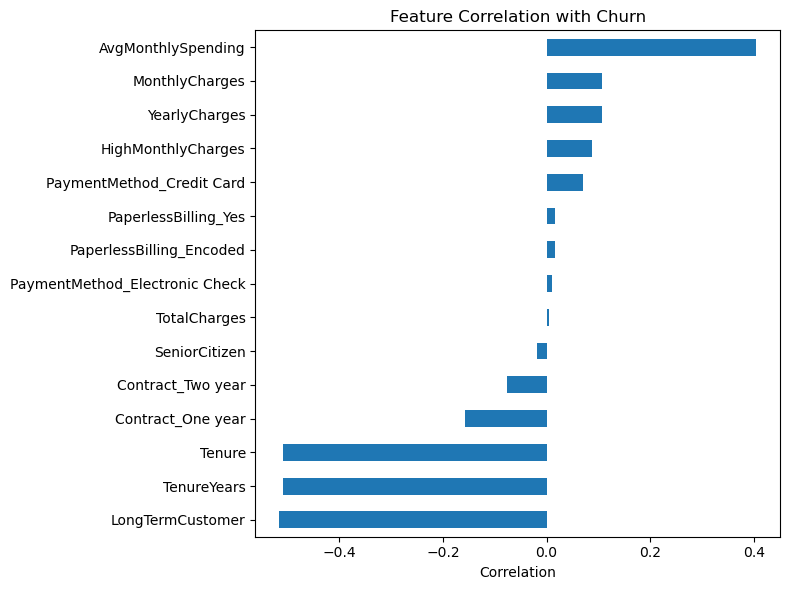

In [25]:
correlation = X.copy()
correlation["Churn"] = y

churn_corr = correlation.corr(numeric_only=True)["Churn"]
churn_corr = churn_corr.drop("Churn").sort_values(
    key=abs,
    ascending=False
)

print(churn_corr)
plt.figure(figsize=(8, 6))

churn_corr.sort_values().plot(kind="barh")

plt.title("Feature Correlation with Churn")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

                           Feature  Importance
0                           Tenure    0.257104
7                      TenureYears    0.245366
5               AvgMonthlySpending    0.139489
9                 LongTermCustomer    0.075364
2                     TotalCharges    0.056347
10               Contract_One year    0.052106
1                   MonthlyCharges    0.051394
6                    YearlyCharges    0.046344
11               Contract_Two year    0.023744
8               HighMonthlyCharges    0.009729
3                    SeniorCitizen    0.009680
13  PaymentMethod_Electronic Check    0.009104
14            PaperlessBilling_Yes    0.008395
4         PaperlessBilling_Encoded    0.008257
12       PaymentMethod_Credit Card    0.007577


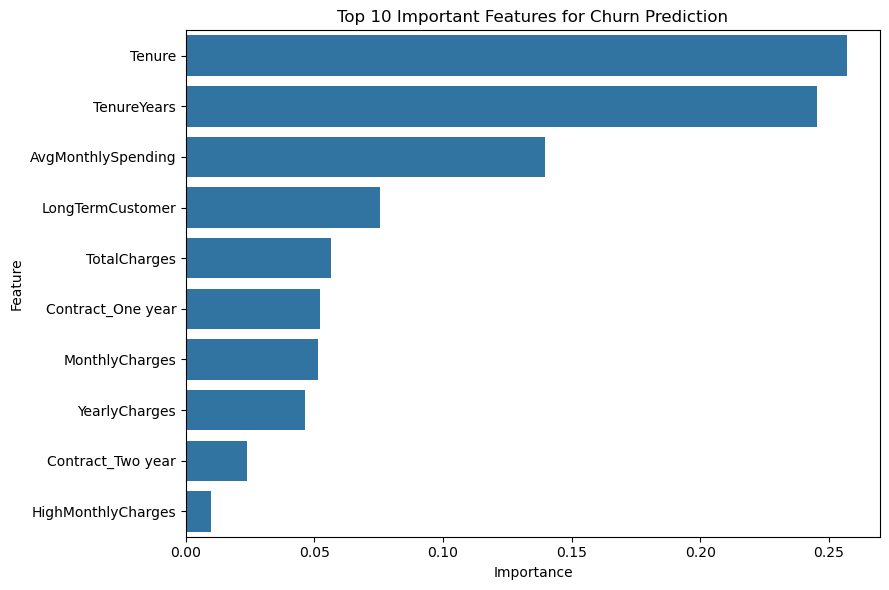

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)
plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Churn Prediction")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split

data = df.drop(
    columns=[
        "CustomerID",
        "Churn",
        "MonthlyCharges_Zscore",
        "PaperlessBilling_Encoded",
        "TenureYears"
    ],
    errors="ignore"
)

y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    data,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 400
Testing rows: 100


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

churn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

churn_pipeline.fit(X_train, y_train)

print("Complete pipeline trained successfully!")

Complete pipeline trained successfully!


In [29]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = churn_pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.97
Precision: 1.0
Recall: 0.7272727272727273
F1 Score: 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        89
           1       1.00      0.73      0.84        11

    accuracy                           0.97       100
   macro avg       0.98      0.86      0.91       100
weighted avg       0.97      0.97      0.97       100



## Conclusion

In this project, I performed data preprocessing and feature engineering on a customer churn dataset containing 500 records. I applied encoding techniques, scaled numerical features, checked for outliers, created new features, and analyzed feature importance.

I then built a machine learning pipeline using Scikit-learn and a Random Forest classifier. The model achieved **97% accuracy**, with a precision of **1.00**, recall of approximately **0.73**, and an F1-score of approximately **0.84** for the churn class.

The model identified 8 out of 11 actual churn customers but missed 3. Since the dataset is imbalanced and the test set contains only 11 churn cases, further evaluation using cross-validation and additional data is recommended.

Overall, this project helped me understand how preprocessing, feature engineering, and proper model evaluation contribute to building a machine learning solution.
